Breast Cancer Classification
In this project, we use machine learning to classify breast tumors as benign or malignant using the Breast Cancer Wisconsin (Diagnostic) dataset. We will explore the data, prepare it for modeling, and develop different machine learning models, including a Neural Network, to compare their performance.

Importing Libraries

In this step, we import the required Python libraries for data manipulation, visualization, preprocessing, and feature selection. We also set the display and visualization styles to make the results easier to read.



In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Feature selection
from sklearn.ensemble import RandomForestClassifier

# Display settings
pd.set_option('display.max_columns', None)

# Visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


Uploading the Dataset

In this step, we upload the dataset file to Google Colab so it can be used for data analysis and model development.

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving wdbc.data to wdbc.data


Loading the Dataset

In this step, we define the column names and load the uploaded dataset using Pandas. The dataset is stored in a DataFrame called df, and its dimensions are displayed to check that it was loaded correctly.

In [ ]:

# Define column names
columns = [
    'ID', 'Diagnosis',
    'Radius_Mean', 'Texture_Mean', 'Perimeter_Mean',
    'Area_Mean', 'Smoothness_Mean', 'Compactness_Mean',
    'Concavity_Mean', 'Concave_Points_Mean',
    'Symmetry_Mean', 'Fractal_Dimension_Mean',

    'Radius_SE', 'Texture_SE', 'Perimeter_SE',
    'Area_SE', 'Smoothness_SE', 'Compactness_SE',
    'Concavity_SE', 'Concave_Points_SE',
    'Symmetry_SE', 'Fractal_Dimension_SE',

    'Radius_Worst', 'Texture_Worst', 'Perimeter_Worst',
    'Area_Worst', 'Smoothness_Worst', 'Compactness_Worst',
    'Concavity_Worst', 'Concave_Points_Worst',
    'Symmetry_Worst', 'Fractal_Dimension_Worst'
]

# Load dataset
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name, header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (569, 32)


Initial Data Exploration

In this step, we examine the dataset using the first five rows, column information, and statistical summary. This helps us understand the dataset structure, data types, feature values, and overall size before starting the cleaning process.

In [ ]:

# Display first five rows
display(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Number of rows and columns
print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


,ID,Diagnosis,Radius_Mean,Texture_Mean,Perimeter_Mean,Area_Mean,Smoothness_Mean,Compactness_Mean,Concavity_Mean,Concave_Points_Mean,Symmetry_Mean,Fractal_Dimension_Mean,Radius_SE,Texture_SE,Perimeter_SE,Area_SE,Smoothness_SE,Compactness_SE,Concavity_SE,Concave_Points_SE,Symmetry_SE,Fractal_Dimension_SE,Radius_Worst,Texture_Worst,Perimeter_Worst,Area_Worst,Smoothness_Worst,Compactness_Worst,Concavity_Worst,Concave_Points_Worst,Symmetry_Worst,Fractal_Dimension_Worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    object 
 2   Radius_Mean              569 non-null    float64
 3   Texture_Mean             569 non-null    float64
 4   Perimeter_Mean           569 non-null    float64
 5   Area_Mean                569 non-null    float64
 6   Smoothness_Mean          569 non-null    float64
 7   Compactness_Mean         569 non-null    float64
 8   Concavity_Mean           569 non-null    float64
 9   Concave_Points_Mean      569 non-null    float64
 10  Symmetry_Mean            569 non-null    float64
 11  Fractal_Dimension_Mean   569 non-null    float64
 12  Radius_SE                569 non-null    float64
 13  Texture_SE               569 non-null    float64
 14  Peri

,ID,Radius_Mean,Texture_Mean,Perimeter_Mean,Area_Mean,Smoothness_Mean,Compactness_Mean,Concavity_Mean,Concave_Points_Mean,Symmetry_Mean,Fractal_Dimension_Mean,Radius_SE,Texture_SE,Perimeter_SE,Area_SE,Smoothness_SE,Compactness_SE,Concavity_SE,Concave_Points_SE,Symmetry_SE,Fractal_Dimension_SE,Radius_Worst,Texture_Worst,Perimeter_Worst,Area_Worst,Smoothness_Worst,Compactness_Worst,Concavity_Worst,Concave_Points_Worst,Symmetry_Worst,Fractal_Dimension_Worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500



Number of rows: 569
Number of columns: 32


Selecting Features and Target Variable

In this step, we separate the input features from the target variable. The ID column is removed because it is only used to identify each sample and is not useful for prediction. The Diagnosis column is selected as the target, while the remaining 30 numerical features are used as input variables.

In [ ]:

# Target variable
target = 'Diagnosis'

# Features
X = df.drop(columns=['ID', 'Diagnosis'])

# Target
y = df['Diagnosis']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.unique())

print("\nFeature names:")
print(X.columns.tolist())


Features shape: (569, 30)
Target shape: (569,)

Target classes:
['M' 'B']

Feature names:
['Radius_Mean', 'Texture_Mean', 'Perimeter_Mean', 'Area_Mean', 'Smoothness_Mean', 'Compactness_Mean', 'Concavity_Mean', 'Concave_Points_Mean', 'Symmetry_Mean', 'Fractal_Dimension_Mean', 'Radius_SE', 'Texture_SE', 'Perimeter_SE', 'Area_SE', 'Smoothness_SE', 'Compactness_SE', 'Concavity_SE', 'Concave_Points_SE', 'Symmetry_SE', 'Fractal_Dimension_SE', 'Radius_Worst', 'Texture_Worst', 'Perimeter_Worst', 'Area_Worst', 'Smoothness_Worst', 'Compactness_Worst', 'Concavity_Worst', 'Concave_Points_Worst', 'Symmetry_Worst', 'Fractal_Dimension_Worst']


Missing Values Analysis

In this step, we check the dataset for missing values using Pandas and visualize them using a heatmap. This helps us identify whether any values need to be handled before continuing with the analysis.

Missing Values:


,0



Total missing values: 0


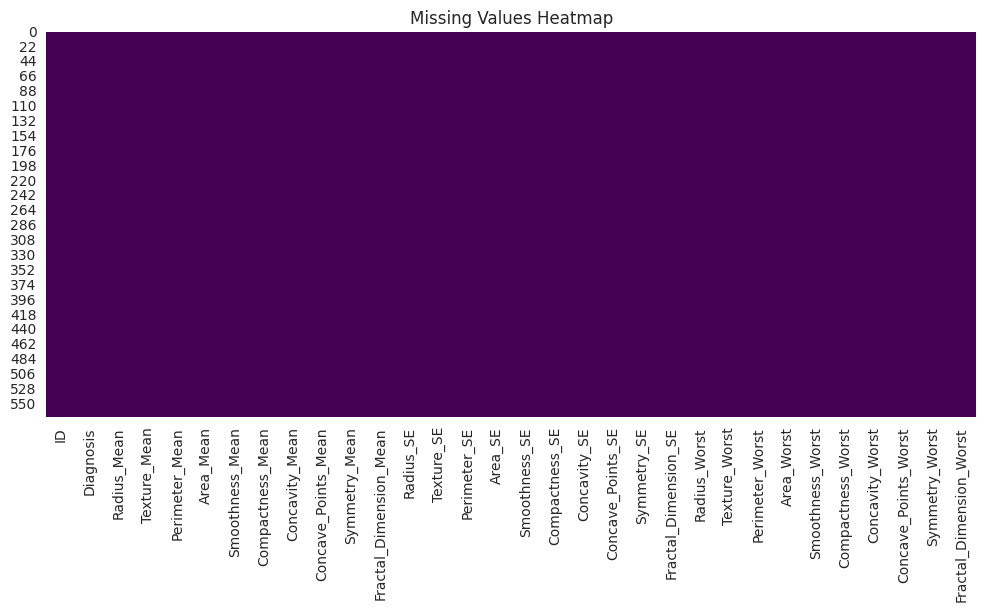

In [ ]:

# Check missing values
missing_values = df.isnull().sum()

print("Missing Values:")
display(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

# Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()


Duplicate Data Analysis

In this step, we check the dataset for duplicate rows. If duplicates are found, they are removed to avoid having repeated records that could affect the model's performance. Finally, we display the dataset shape after this check.


In [18]:

# Count duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

# Remove duplicates if found
if duplicates > 0:
    df = df.drop_duplicates().copy()
    print("Duplicates removed.")
else:
    print("No duplicate rows found.")

print("Dataset shape after duplicate check:", df.shape)


Number of duplicate rows: 0
No duplicate rows found.
Dataset shape after duplicate check: (569, 35)


Checking Data Types and Incorrect Values

In this step, we examine the data types, diagnosis categories, and numerical values to identify any inconsistent or invalid data. We also check for negative values in the numerical features to make sure the data is suitable for further analysis.

In [19]:

# Check data types
print("Data Types:")
print(df.dtypes)

# Check diagnosis categories
print("\nDiagnosis Categories:")
print(df['Diagnosis'].value_counts())

# Check invalid diagnosis values
print("\nInvalid Diagnosis Values:")
print(df[~df['Diagnosis'].isin(['M', 'B'])])

# Check negative numerical values
numerical_columns = X.columns

negative_counts = (df[numerical_columns] < 0).sum()

print("\nNegative Values:")
display(negative_counts[negative_counts > 0])


Data Types:
ID                               int64
Diagnosis                       object
Radius_Mean                    float64
Texture_Mean                   float64
Perimeter_Mean                 float64
Area_Mean                      float64
Smoothness_Mean                float64
Compactness_Mean               float64
Concavity_Mean                 float64
Concave_Points_Mean            float64
Symmetry_Mean                  float64
Fractal_Dimension_Mean         float64
Radius_SE                      float64
Texture_SE                     float64
Perimeter_SE                   float64
Area_SE                        float64
Smoothness_SE                  float64
Compactness_SE                 float64
Concavity_SE                   float64
Concave_Points_SE              float64
Symmetry_SE                    float64
Fractal_Dimension_SE           float64
Radius_Worst                   float64
Texture_Worst                  float64
Perimeter_Worst                float64
Area_Worst   

,0


Target Class Distribution

In this step, we calculate the number of samples in each diagnosis category and visualize the distribution using a count plot. This helps us understand the balance between benign and malignant cases.

Diagnosis
B    357
M    212
Name: count, dtype: int64


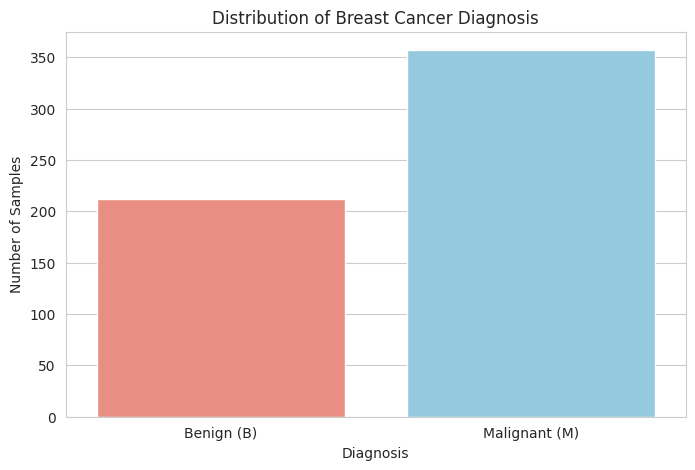

In [ ]:

# Count each diagnosis class
print(df['Diagnosis'].value_counts())

# Plot diagnosis distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Diagnosis',
    hue='Diagnosis',
    palette={'B': 'skyblue', 'M': 'salmon'},
    legend=False
)

plt.title("Distribution of Breast Cancer Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ['Benign (B)', 'Malignant (M)'])

plt.savefig("diagnosis_distribution.png",
            dpi=300, bbox_inches='tight')

plt.show()


Outlier Detection Using IQR

In this step, we use the Interquartile Range (IQR) method to identify potential outliers in the numerical features. The method uses the first and third quartiles to detect values outside the expected range. The number of outliers is calculated for each feature.

In [ ]:

# Calculate IQR
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

# Identify outliers
outlier_mask = (
    (X < (Q1 - 1.5 * IQR)) |
    (X > (Q3 + 1.5 * IQR))
)

outlier_counts = outlier_mask.sum()

print("Outliers per feature:")
display(outlier_counts.sort_values(ascending=False))

print("\nTotal outlier values:", outlier_mask.sum().sum())


Outliers per feature:


,0
Area_SE,65
Radius_SE,38
Perimeter_SE,38
Area_Worst,35
Smoothness_SE,30
Fractal_Dimension_SE,28
Compactness_SE,28
Symmetry_SE,27
Area_Mean,25
Fractal_Dimension_Worst,24



Total outlier values: 608


Outlier Visualization Using Boxplots

In this step, we use boxplots to visualize the distribution of selected numerical features and identify potential outliers. This helps us understand the spread of the data and detect unusual values in the measurements.

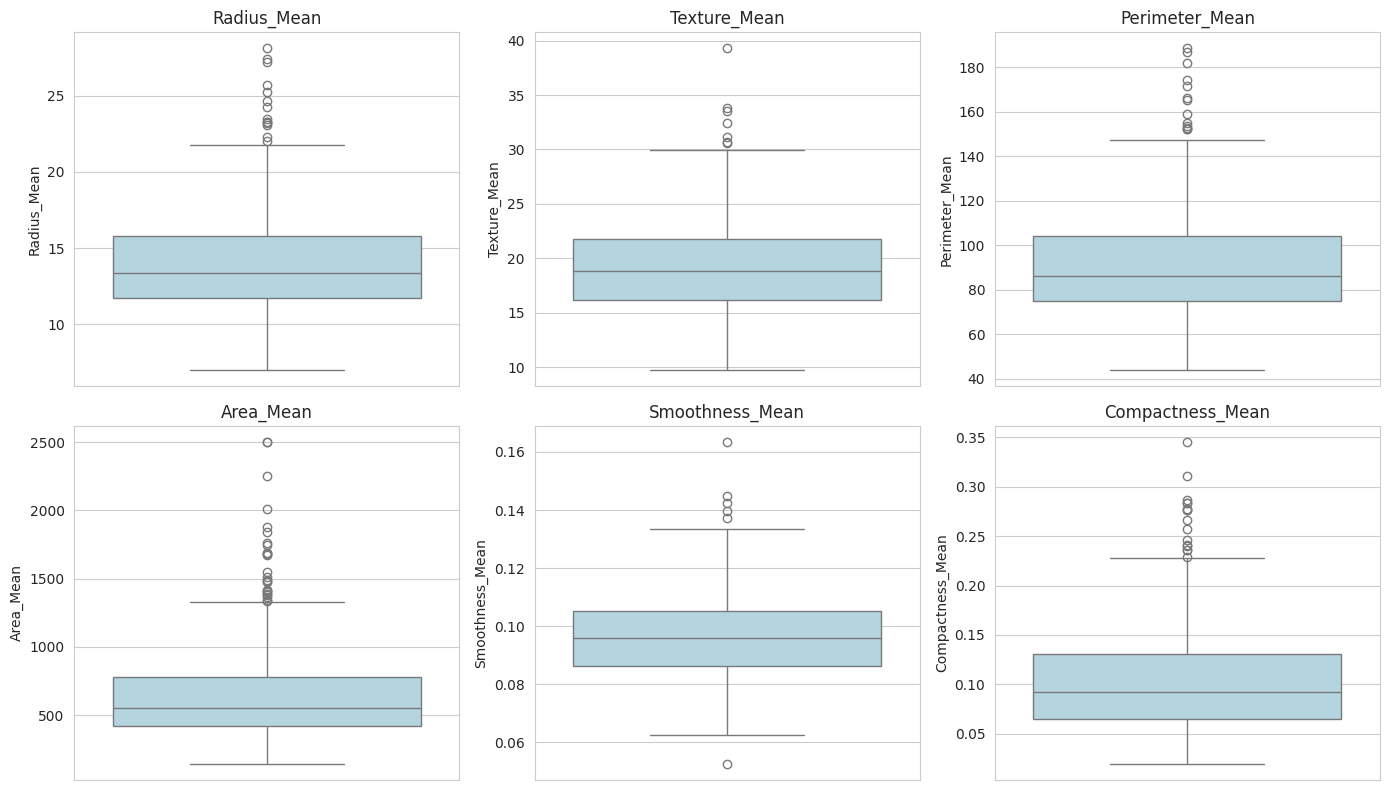

In [ ]:

# Select some important features
selected_features = [
    'Radius_Mean',
    'Texture_Mean',
    'Perimeter_Mean',
    'Area_Mean',
    'Smoothness_Mean',
    'Compactness_Mean'
]

plt.figure(figsize=(14, 8))

for i, feature in enumerate(selected_features):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[feature], color='lightblue')
    plt.title(feature)

plt.tight_layout()

plt.savefig("outliers_boxplots.png",
            dpi=300, bbox_inches='tight')

plt.show()


Creating New Features

In this step, we create three additional features by calculating ratios between selected numerical measurements. These new features are intended to provide additional information about the relationships between tumor characteristics and may help improve classification performance.

In [ ]:

# Create new features
df['Area_Radius_Ratio'] = (
    df['Area_Mean'] / (df['Radius_Mean'] + 1e-8)
)

df['Concavity_Compactness_Ratio'] = (
    df['Concavity_Mean'] /
    (df['Compactness_Mean'] + 1e-8)
)

df['Worst_Mean_Area_Ratio'] = (
    df['Area_Worst'] / (df['Area_Mean'] + 1e-8)
)

print("New features created successfully!")

display(df.head())


New features created successfully!


,ID,Diagnosis,Radius_Mean,Texture_Mean,Perimeter_Mean,Area_Mean,Smoothness_Mean,Compactness_Mean,Concavity_Mean,Concave_Points_Mean,Symmetry_Mean,Fractal_Dimension_Mean,Radius_SE,Texture_SE,Perimeter_SE,Area_SE,Smoothness_SE,Compactness_SE,Concavity_SE,Concave_Points_SE,Symmetry_SE,Fractal_Dimension_SE,Radius_Worst,Texture_Worst,Perimeter_Worst,Area_Worst,Smoothness_Worst,Compactness_Worst,Concavity_Worst,Concave_Points_Worst,Symmetry_Worst,Fractal_Dimension_Worst,Area_Radius_Ratio,Concavity_Compactness_Ratio,Worst_Mean_Area_Ratio
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,55.642023,1.081052,2.016983
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,64.462810,1.105035,1.475113
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,61.097004,1.234521,1.420615
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,33.809107,0.850299,1.470344
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,63.923115,1.490964,1.214341


Correlation Analysis

In this step, we calculate the correlation between numerical features and visualize the results using a heatmap. This helps us understand the relationships between features and identify highly correlated variables that may contain similar information.

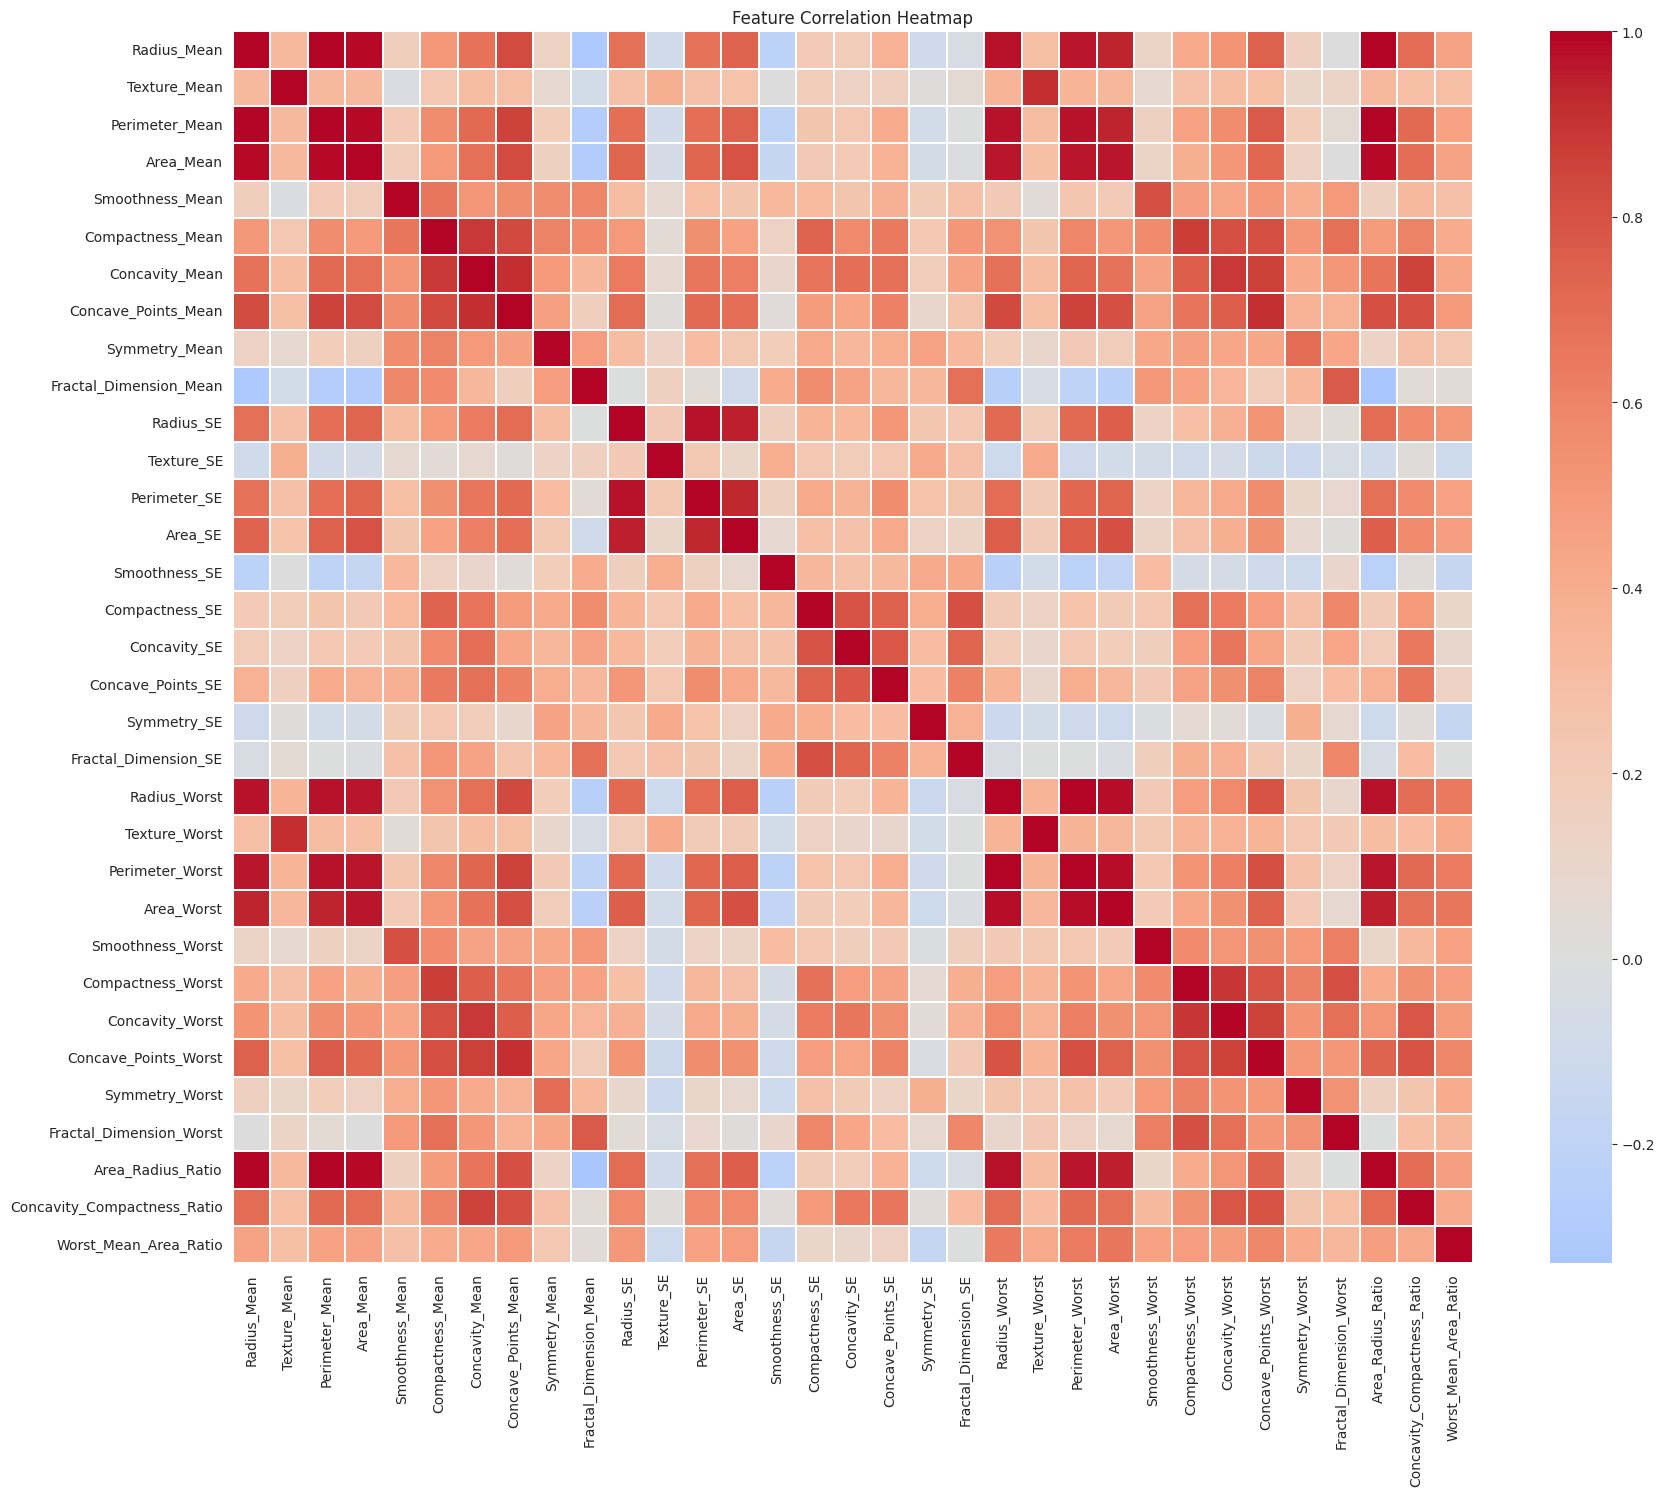

In [ ]:

# Select numerical features
correlation = df.drop(
    columns=['ID', 'Diagnosis']
).corr()

# Plot correlation heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    linewidths=0.2
)

plt.title("Feature Correlation Heatmap")

plt.savefig("correlation_heatmap.png",
            dpi=300, bbox_inches='tight')

plt.show()


Feature Comparison by Diagnosis

In this step, we compare selected numerical features between benign and malignant tumors using boxplots. This helps us observe differences in feature distributions between the two diagnosis groups and understand which measurements may be useful for classification.

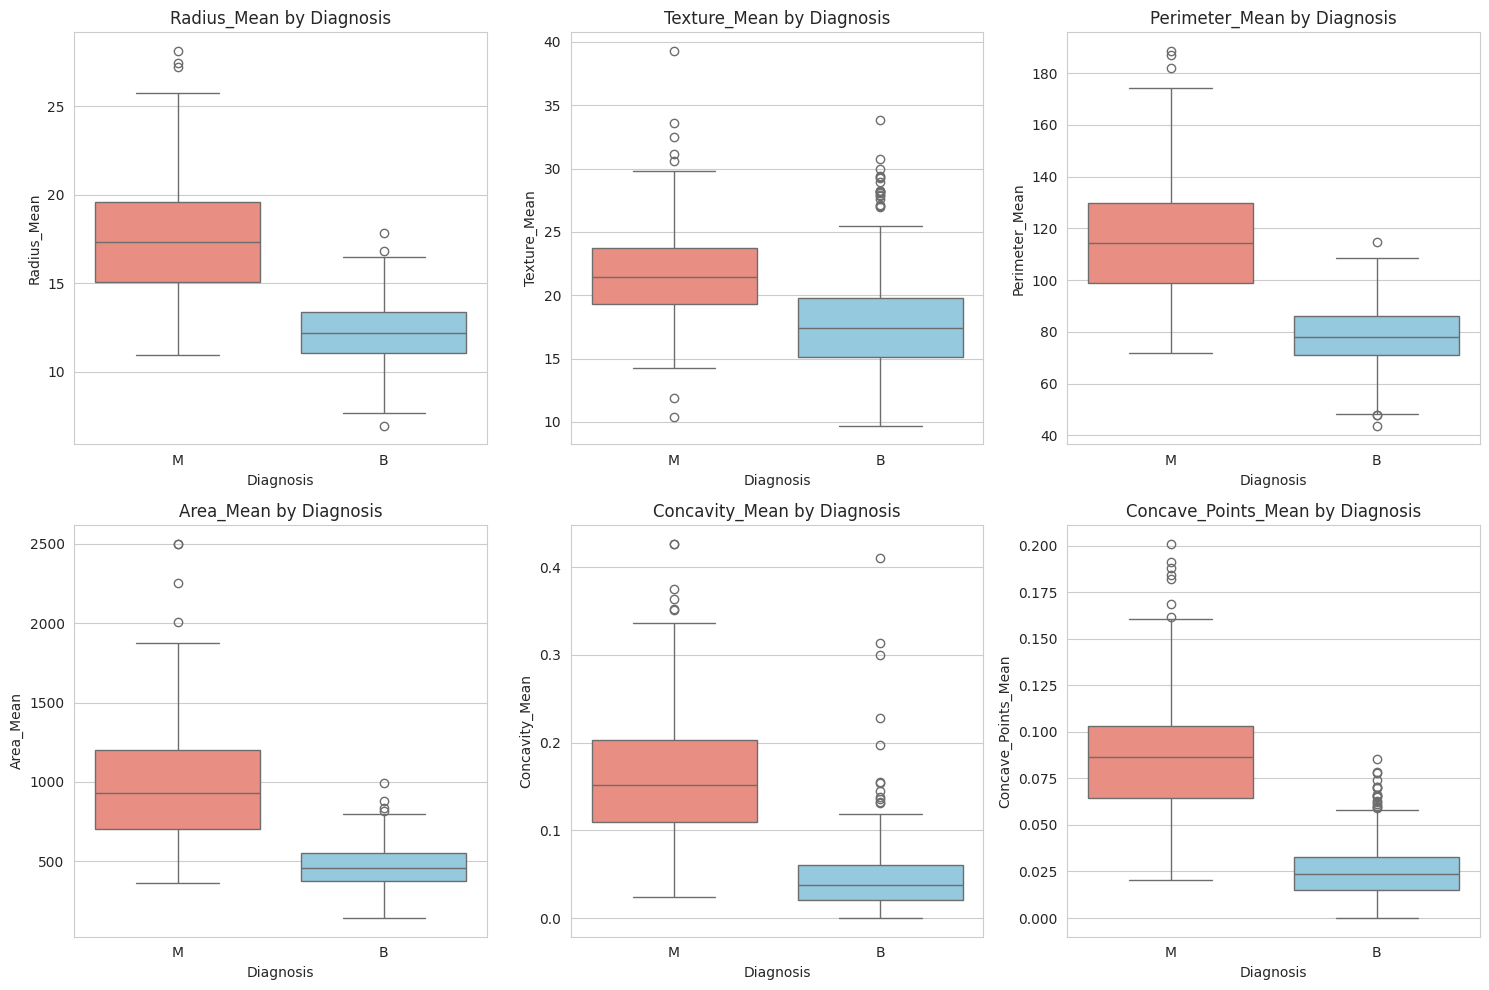

In [ ]:


features_to_plot = [
    'Radius_Mean',
    'Texture_Mean',
    'Perimeter_Mean',
    'Area_Mean',
    'Concavity_Mean',
    'Concave_Points_Mean'
]

plt.figure(figsize=(15, 10))

for i, feature in enumerate(features_to_plot):
    plt.subplot(2, 3, i + 1)

    sns.boxplot(
        data=df,
        x='Diagnosis',
        y=feature,
        hue='Diagnosis',
        palette={'B': 'skyblue', 'M': 'salmon'},
        legend=False
    )

    plt.title(f'{feature} by Diagnosis')

plt.tight_layout()

plt.savefig("features_by_diagnosis.png",
            dpi=300, bbox_inches='tight')

plt.show()


Feature Importance Using Random Forest

In this step, we use a Random Forest classifier to identify the most important features for breast cancer classification. The model is trained on a temporary training subset, and the feature importance scores are calculated and sorted. The top 10 features are then visualized using a bar plot to highlight the measurements that contribute most to the classification task.

Top 10 Important Features:


,Feature,Importance
20,Radius_Worst,0.110077
7,Concave_Points_Mean,0.105766
23,Area_Worst,0.105489
22,Perimeter_Worst,0.094092
27,Concave_Points_Worst,0.084077
32,Worst_Mean_Area_Ratio,0.051694
30,Area_Radius_Ratio,0.049806
3,Area_Mean,0.041705
2,Perimeter_Mean,0.041117
0,Radius_Mean,0.040460


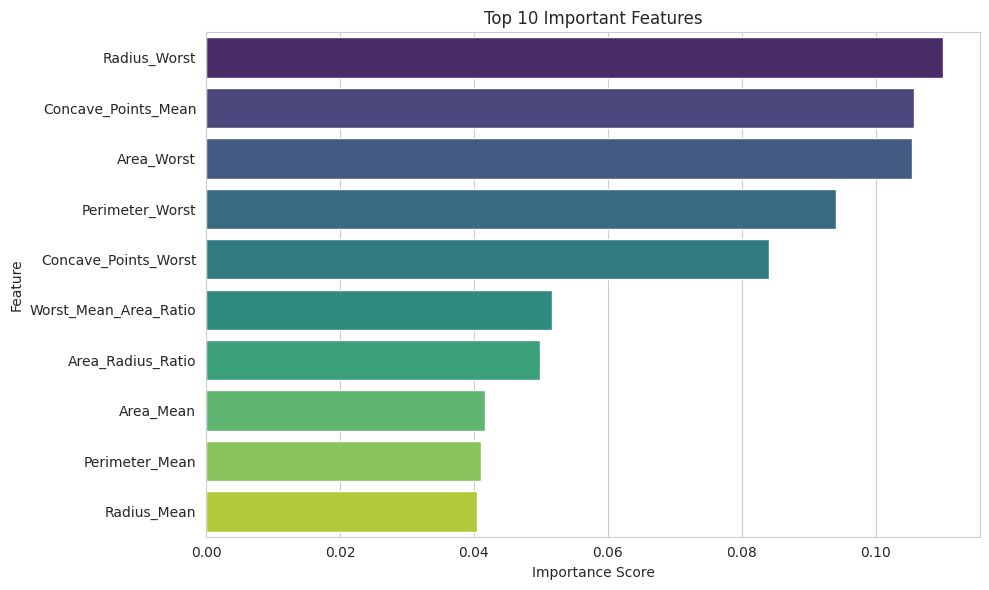

In [ ]:

# Prepare features and target
# Exclude ID, Diagnosis, and Diagnosis_Encoded
X_importance = df.drop(
    columns=['ID', 'Diagnosis', 'Diagnosis_Encoded'],
    errors='ignore'
)

y_importance = df['Diagnosis']

# Temporary split for exploratory analysis
from sklearn.model_selection import train_test_split

X_train_exp, X_temp_exp, y_train_exp, y_temp_exp = train_test_split(
    X_importance,
    y_importance,
    test_size=0.30,
    random_state=42,
    stratify=y_importance
)

# Train Random Forest using training data only
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train_exp, y_train_exp)

# Calculate feature importance
importance = pd.DataFrame({
    'Feature': X_train_exp.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 10 Important Features:")
display(importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches='tight')
plt.show()


Encoding the Target Variable

In this step, we convert the diagnosis labels into numerical values to make them suitable for machine learning models. Benign (B) is encoded as 0, while Malignant (M) is encoded as 1.

In [ ]:

# Encode target variable
df['Diagnosis_Encoded'] = df['Diagnosis'].map({
    'B': 0,
    'M': 1
})

print("Target Encoding:")
print(df[['Diagnosis', 'Diagnosis_Encoded']].head())


Target Encoding:
  Diagnosis  Diagnosis_Encoded
0         M                  1
1         M                  1
2         M                  1
3         M                  1
4         M                  1


Preparing Features and Target for Modeling

In this step, we prepare the final input features and target variable for the modeling stage. The ID and original Diagnosis columns are removed, while the encoded diagnosis is used as the target. We also initialize StandardScaler, which will be fitted on the training data after splitting to avoid data leakage.



In [ ]:

# Prepare final features and target
X_final = df.drop(
    columns=['ID', 'Diagnosis', 'Diagnosis_Encoded']
)

y_final = df['Diagnosis_Encoded']

# Initialize scaler
scaler = StandardScaler()

print("Features are ready for scaling.")
print("Scaling will be fitted on the training data only after data splitting.")

print("Final Features Shape:", X_final.shape)
print("Final Target Shape:", y_final.shape)


Features are ready for scaling.
Scaling will be fitted on the training data only after data splitting.
Final Features Shape: (569, 33)
Final Target Shape: (569,)


Saving the Prepared Dataset

In this step, we save the prepared dataset as a CSV file so it can be used in the next stages of the project. The file is also downloaded from Google Colab for later use.

In [ ]:

# Save prepared dataset
df.to_csv(
    'breast_cancer_cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

# Download file
from google.colab import files

files.download('breast_cancer_cleaned.csv')


Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Checking Target Class Distribution

In this step, we calculate the number and percentage of samples in each diagnosis category. This provides a final overview of the class distribution before moving to the next stage of the project.

In [ ]:
print("Diagnosis Distribution:")
print(df['Diagnosis'].value_counts())

print("\nClass Percentages:")
print(df['Diagnosis'].value_counts(normalize=True) * 100)

Diagnosis Distribution:
Diagnosis
B    357
M    212
Name: count, dtype: int64

Class Percentages:
Diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


Summary of Outlier Detection

In this step, we display the total number of detected outliers and their distribution across the numerical features. This helps summarize the outlier analysis and identify which features contain the highest number of unusual values.

In [ ]:
print("Total Outliers:")
print(outlier_mask.sum().sum())

print("\nOutliers per Feature:")
display(outlier_counts.sort_values(ascending=False))

Total Outliers:
608

Outliers per Feature:


,0
Area_SE,65
Radius_SE,38
Perimeter_SE,38
Area_Worst,35
Smoothness_SE,30
Fractal_Dimension_SE,28
Compactness_SE,28
Symmetry_SE,27
Area_Mean,25
Fractal_Dimension_Worst,24


Saving the Prepared Dataset

In this final step, we save the prepared dataset as a CSV file after removing the encoded target column. This file contains the original diagnosis labels and the prepared features, making it ready for use in the next project stages.

In [ ]:
# Save prepared dataset
df_stage1 = df.drop(
    columns=['Diagnosis_Encoded'],
    errors='ignore'
)

df_stage1.to_csv(
    'wdbc_prepared_stage1.csv',
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


Part 2: Data Splitting and Model Development

In this part, we continue working with the prepared breast cancer dataset and start preparing the data for machine learning model development.

Uploading the Prepared Dataset

In this step, we upload the prepared dataset from Part 1 to Google Colab to continue with data splitting and model development.

In [5]:

from google.colab import files
import pandas as pd

uploaded = files.upload()


Saving wdbc.data to wdbc.data


Loading the Prepared Dataset

In this step, we define the column names and load the uploaded CSV file into a Pandas DataFrame. We then display the dataset dimensions to verify that it has been loaded correctly.

In [20]:

columns = [
    'ID', 'Diagnosis',
    'Radius_Mean', 'Texture_Mean', 'Perimeter_Mean',
    'Area_Mean', 'Smoothness_Mean', 'Compactness_Mean',
    'Concavity_Mean', 'Concave_Points_Mean',
    'Symmetry_Mean', 'Fractal_Dimension_Mean',
    'Radius_SE', 'Texture_SE', 'Perimeter_SE',
    'Area_SE', 'Smoothness_SE', 'Compactness_SE',
    'Concavity_SE', 'Concave_Points_SE',
    'Symmetry_SE', 'Fractal_Dimension_SE',
    'Radius_Worst', 'Texture_Worst', 'Perimeter_Worst',
    'Area_Worst', 'Smoothness_Worst', 'Compactness_Worst',
    'Concavity_Worst', 'Concave_Points_Worst',
    'Symmetry_Worst', 'Fractal_Dimension_Worst'
]

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name, header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (569, 32)


Feature Engineering

In this step, we recreate the three additional features from Part 1 using ratios between selected measurements. These features are added to the dataset to provide extra information for the machine learning models.

In [7]:

df['Area_Radius_Ratio'] = (
    df['Area_Mean'] / (df['Radius_Mean'] + 1e-8)
)

df['Concavity_Compactness_Ratio'] = (
    df['Concavity_Mean'] /
    (df['Compactness_Mean'] + 1e-8)
)

df['Worst_Mean_Area_Ratio'] = (
    df['Area_Worst'] / (df['Area_Mean'] + 1e-8)
)

print("Feature engineering completed!")
print("Dataset shape:", df.shape)


Feature engineering completed!
Dataset shape: (569, 35)


Separating Features and Target Variable

In this step, we separate the input features from the target variable. The ID and Diagnosis columns are excluded from the input features, while the diagnosis labels are converted into numerical values (Benign = 0, Malignant = 1). We also check the shapes and class distribution.

In [8]:

X = df.drop(
    columns=['ID', 'Diagnosis'],
    errors='ignore'
).copy()

y = df['Diagnosis'].map({'B': 0, 'M': 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print(y.value_counts())


Features Shape: (569, 33)
Target Shape: (569,)
Diagnosis
0    357
1    212
Name: count, dtype: int64


Splitting the Dataset

In this step, we divide the dataset into three sets: 70% for training, 15% for validation, and 15% for testing. We use stratified splitting to maintain the same class distribution across all three sets. This helps ensure a fair evaluation of the machine learning models.

In [9]:

from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)


Training Set: (398, 33)
Validation Set: (85, 33)
Testing Set: (86, 33)


Checking Class Distribution After Splitting

In this step, we check the number of benign and malignant samples in the training, validation, and testing sets. This ensures that both classes are represented in all three sets after splitting.

In [10]:

print("Training Class Distribution:")
print(y_train.value_counts())

print("\nValidation Class Distribution:")
print(y_val.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


Training Class Distribution:
Diagnosis
0    250
1    148
Name: count, dtype: int64

Validation Class Distribution:
Diagnosis
0    53
1    32
Name: count, dtype: int64

Testing Class Distribution:
Diagnosis
0    54
1    32
Name: count, dtype: int64


Visualizing Dataset Splitting

In this step, we visualize the number of samples in the training, validation, and testing sets using a bar chart. This provides a clear comparison of the dataset sizes after splitting.

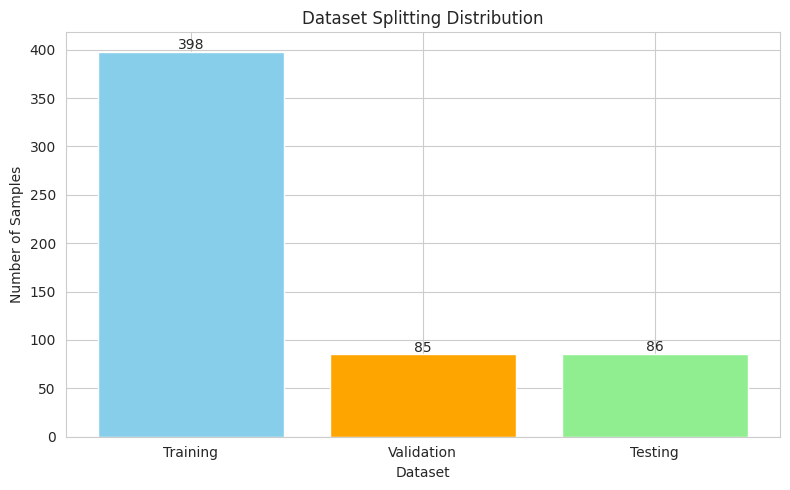

In [11]:

split_names = ['Training', 'Validation', 'Testing']

split_sizes = [
    len(X_train),
    len(X_val),
    len(X_test)
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    split_names,
    split_sizes,
    color=['skyblue', 'orange', 'lightgreen']
)

plt.title("Dataset Splitting Distribution")
plt.xlabel("Dataset")
plt.ylabel("Number of Samples")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 3,
        int(bar.get_height()),
        ha='center'
    )

plt.tight_layout()
plt.show()


Feature Scaling Using StandardScaler

In this step, we apply StandardScaler to standardize the numerical features. The scaler is fitted only on the training data, then applied to the validation and testing sets using the same parameters. This ensures that all features have a similar scale and helps prevent data leakage.

In [12]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)


Feature scaling completed successfully!
Training: (398, 33)
Validation: (85, 33)
Testing: (86, 33)


Importing Machine Learning Models

In this step, we import the machine learning algorithms that will be used in our project: Logistic Regression, Random Forest, and Neural Network. We also import Accuracy Score to measure model performance.

In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

print("Models imported successfully!")


Models imported successfully!


Training Logistic Regression Model

In this step, we train the Logistic Regression model using the scaled training data. We then evaluate its performance on both training and validation sets using accuracy score to check how well the model performs on unseen data.

In [14]:

log_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

log_train_pred = log_model.predict(X_train_scaled)
log_val_pred = log_model.predict(X_val_scaled)

print("Logistic Regression")

print("Training Accuracy:",
      accuracy_score(y_train, log_train_pred))

print("Validation Accuracy:",
      accuracy_score(y_val, log_val_pred))


Logistic Regression
Training Accuracy: 0.9874371859296482
Validation Accuracy: 0.9647058823529412


Training Random Forest Model

In this step, we train the Random Forest model using the training data. We then calculate the training and validation accuracy to evaluate its performance and compare the results with Logistic Regression.

In [15]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_val_pred = rf_model.predict(X_val)

print("Random Forest")

print("Training Accuracy:",
      accuracy_score(y_train, rf_train_pred))

print("Validation Accuracy:",
      accuracy_score(y_val, rf_val_pred))


Random Forest
Training Accuracy: 1.0
Validation Accuracy: 0.9647058823529412


Training Neural Network Model

In this step, we build and train a Neural Network using the MLPClassifier algorithm. The model uses two hidden layers with 64 and 32 neurons, respectively. We use the ReLU activation function and Adam optimizer. Early stopping is also enabled to help prevent overfitting. Finally, we evaluate the model using training and validation accuracy.

In [21]:

nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

nn_train_pred = nn_model.predict(X_train_scaled)
nn_val_pred = nn_model.predict(X_val_scaled)

print("Neural Network")

print("Training Accuracy:",
      accuracy_score(y_train, nn_train_pred))

print("Validation Accuracy:",
      accuracy_score(y_val, nn_val_pred))


Neural Network
Training Accuracy: 0.9396984924623115
Validation Accuracy: 0.9411764705882353


In [47]:
print("Training Accuracy:",
      accuracy_score(y_train, nn_train_pred))

print("Validation Accuracy:",
      accuracy_score(y_val, nn_val_pred))

Training Accuracy: 0.9396984924623115
Validation Accuracy: 0.9411764705882353


Initial Model Performance Comparison

In this step, we create a comparison table showing the training and validation accuracy of the three models. This helps us compare their initial performance and identify possible differences between training and validation results.

In [17]:

initial_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Neural Network'
    ],

    'Training Accuracy': [
        accuracy_score(y_train, log_train_pred),
        accuracy_score(y_train, rf_train_pred),
        accuracy_score(y_train, nn_train_pred)
    ],

    'Validation Accuracy': [
        accuracy_score(y_val, log_val_pred),
        accuracy_score(y_val, rf_val_pred),
        accuracy_score(y_val, nn_val_pred)
    ]
})

display(initial_results)


,Model,Training Accuracy,Validation Accuracy
0,Logistic Regression,0.987437,0.964706
1,Random Forest,1.000000,0.964706
2,Neural Network,0.939698,0.941176


Part 2 Summary

In this part, we prepared the dataset for model development, divided it into training, validation, and testing sets, and applied feature scaling. We also trained three machine learning models: Logistic Regression, Random Forest, and Neural Network. Their initial performance was compared using training and validation accuracy.

The next part will focus on hyperparameter tuning and model optimization.

Part 3: Model Training and Hyperparameter Optimization

In this part, we focus on improving the performance of the three selected machine learning models through hyperparameter tuning and cross-validation. We also analyze their performance to identify possible overfitting or underfitting.

Importing Required Libraries

In this step, we import the required tools for hyperparameter optimization, cross-validation, and model evaluation.

In [26]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Cross-Validation Setup

We use Stratified K-Fold Cross-Validation with 5 folds to evaluate different hyperparameter combinations while maintaining the class distribution in each fold.

In [27]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Logistic Regression Hyperparameter Tuning

# In this step, we use GridSearchCV to find the best hyperparameters for the Logistic Regression model. We test different values of regularization strength (C) and penalty types using 5-fold cross-validation.

In [28]:
log_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

log_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    param_grid=log_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

log_grid.fit(X_train_scaled, y_train)

best_log_model = log_grid.best_estimator_

print("Best Logistic Regression Parameters:")
print(log_grid.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(log_grid.best_score_)

Best Logistic Regression Parameters:
{'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}

Best Cross-Validation Accuracy:
0.9798734177215189


Random Forest Hyperparameter Tuning

In this step, we use GridSearchCV to find the best hyperparameters for the Random Forest model. Different values of the number of trees, maximum depth, and minimum samples are tested using 5-fold cross-validation.

In [31]:
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

best_rf_model = rf_grid.best_estimator_

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(rf_grid.best_score_)

Best Random Forest Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation Accuracy:
0.9521835443037976


Neural Network Hyperparameter Tuning

In this step, we use GridSearchCV to test different Neural Network architectures, activation functions, and learning rates. The best combination is selected based on 5-fold cross-validation accuracy.

In [32]:
nn_param_grid = {
    'hidden_layer_sizes': [(32,), (64, 32), (100, 50)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001],
    'learning_rate_init': [0.001, 0.01]
}

nn_grid = GridSearchCV(
    MLPClassifier(
        solver='adam',
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=42
    ),
    param_grid=nn_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

nn_grid.fit(X_train_scaled, y_train)

best_nn_model = nn_grid.best_estimator_

print("Best Neural Network Parameters:")
print(nn_grid.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(nn_grid.best_score_)

Best Neural Network Parameters:
{'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (100, 50), 'learning_rate_init': 0.01}

Best Cross-Validation Accuracy:
0.9748734177215189


Comparing Optimized Models

In this step, we compare the best cross-validation accuracy of the three models to identify which model achieved the highest performance during hyperparameter tuning.

In [33]:
cv_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Neural Network'
    ],
    'Best CV Accuracy': [
        log_grid.best_score_,
        rf_grid.best_score_,
        nn_grid.best_score_
    ]
})

display(
    cv_results.sort_values(
        by='Best CV Accuracy',
        ascending=False
    )
)

,Model,Best CV Accuracy
0,Logistic Regression,0.979873
2,Neural Network,0.974873
1,Random Forest,0.952184


Training and Validation Performance

In this step, we evaluate the optimized models using the training and validation sets. Comparing their accuracy and F1-scores helps us understand their performance and identify possible overfitting or underfitting.

In [34]:
best_models = {
    'Logistic Regression': (
        best_log_model, X_train_scaled, X_val_scaled
    ),
    'Random Forest': (
        best_rf_model, X_train, X_val
    ),
    'Neural Network': (
        best_nn_model, X_train_scaled, X_val_scaled
    )
}

performance_results = []

for name, (model, Xtr, Xv) in best_models.items():

    train_pred = model.predict(Xtr)
    val_pred = model.predict(Xv)

    performance_results.append({
        'Model': name,
        'Training Accuracy': accuracy_score(y_train, train_pred),
        'Validation Accuracy': accuracy_score(y_val, val_pred),
        'Training F1-score': f1_score(y_train, train_pred),
        'Validation F1-score': f1_score(y_val, val_pred)
    })

performance_df = pd.DataFrame(performance_results)

display(performance_df)

,Model,Training Accuracy,Validation Accuracy,Training F1-score,Validation F1-score
0,Logistic Regression,0.987437,0.964706,0.982935,0.950820
1,Random Forest,1.000000,0.964706,1.000000,0.950820
2,Neural Network,0.979899,0.941176,0.972414,0.918033


Neural Network Training and Validation Curves

In this step, we plot the Neural Network training loss and validation accuracy over different training iterations. These curves help us understand the learning process and identify possible overfitting or underfitting.

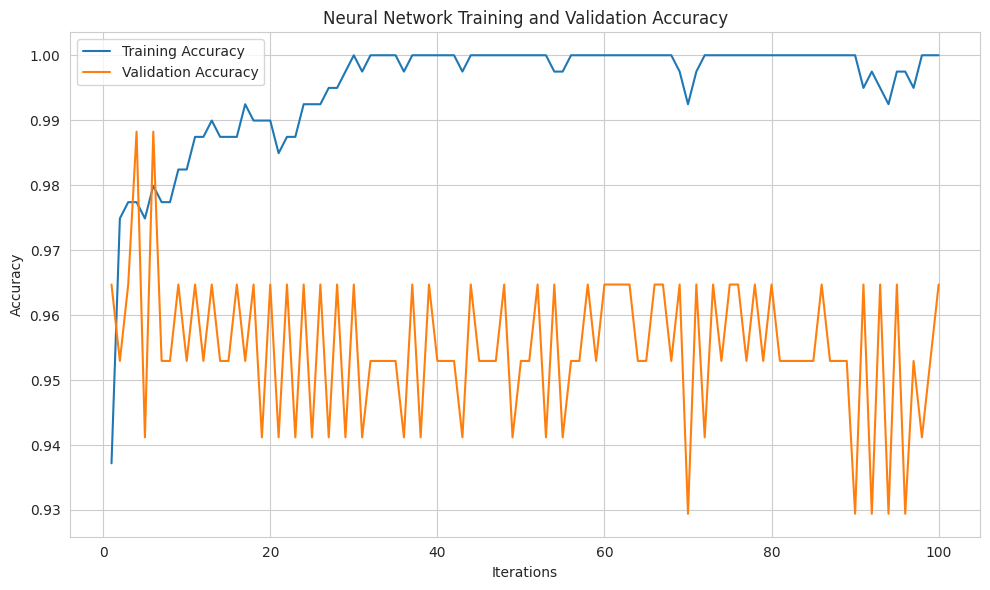

In [46]:
import warnings
from sklearn.exceptions import ConvergenceWarning

nn_curve_model = MLPClassifier(
    **nn_grid.best_params_,
    solver='adam',
    max_iter=1,
    warm_start=True,
    early_stopping=False,
    random_state=42
)

train_accuracies = []
val_accuracies = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    for epoch in range(100):

        nn_curve_model.fit(X_train_scaled, y_train)

        train_pred = nn_curve_model.predict(X_train_scaled)
        val_pred = nn_curve_model.predict(X_val_scaled)

        train_accuracies.append(
            accuracy_score(y_train, train_pred)
        )

        val_accuracies.append(
            accuracy_score(y_val, val_pred)
        )

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 101),
    train_accuracies,
    label='Training Accuracy'
)

plt.plot(
    range(1, 101),
    val_accuracies,
    label='Validation Accuracy'
)

plt.title('Neural Network Training and Validation Accuracy')
plt.xlabel('Iterations')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Part 3 Summary

In this part, we optimized the three machine learning models using GridSearchCV and 5-fold cross-validation. We also compared their training and validation performance and visualized the Neural Network learning curves to understand its training behavior.

Part 4: Final Model Evaluation and Comparison

In this part, we evaluate the optimized machine learning models using the test dataset. We use different evaluation metrics to compare their performance and identify the most suitable model for breast cancer classification.

Importing Evaluation Metrics

In this step, we import the evaluation metrics needed to measure and compare the performance of the selected models.

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Preparing the Optimized Models

In this step, we collect the best versions of the three optimized models to evaluate them using the same test dataset.

In [38]:
final_models = {
    'Logistic Regression': (
        best_log_model, X_test_scaled
    ),

    'Random Forest': (
        best_rf_model, X_test
    ),

    'Neural Network': (
        best_nn_model, X_test_scaled
    )
}

Evaluating Models on the Test Set

In this step, we evaluate each optimized model using the unseen test data. We calculate Accuracy, Precision, Recall, F1-score, and ROC-AUC to get a complete understanding of model performance.

In [39]:
final_results = []
test_predictions = {}
test_probabilities = {}

for name, (model, X_test_input) in final_models.items():

    y_pred = model.predict(X_test_input)
    y_prob = model.predict_proba(X_test_input)[:, 1]

    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob

    final_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9884,0.9697,1.0000,0.9846,1.0
1,Random Forest,0.9767,1.0000,0.9375,0.9677,1.0
2,Neural Network,0.9884,1.0000,0.9688,0.9841,1.0


Classification Reports

In this step, we generate a classification report for each model. The reports show Precision, Recall, F1-score, and the number of samples in each class.

In [40]:
for name in final_models:

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        test_predictions[name],
        target_names=['Benign', 'Malignant']
    ))


Logistic Regression
              precision    recall  f1-score   support

      Benign       1.00      0.98      0.99        54
   Malignant       0.97      1.00      0.98        32

    accuracy                           0.99        86
   macro avg       0.98      0.99      0.99        86
weighted avg       0.99      0.99      0.99        86


Random Forest
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        54
   Malignant       1.00      0.94      0.97        32

    accuracy                           0.98        86
   macro avg       0.98      0.97      0.97        86
weighted avg       0.98      0.98      0.98        86


Neural Network
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99        54
   Malignant       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.9

Confusion Matrix Comparison

In this step, we visualize the confusion matrix of each model to examine the number of correctly and incorrectly classified benign and malignant cases. This helps us understand the types of classification errors made by each model.





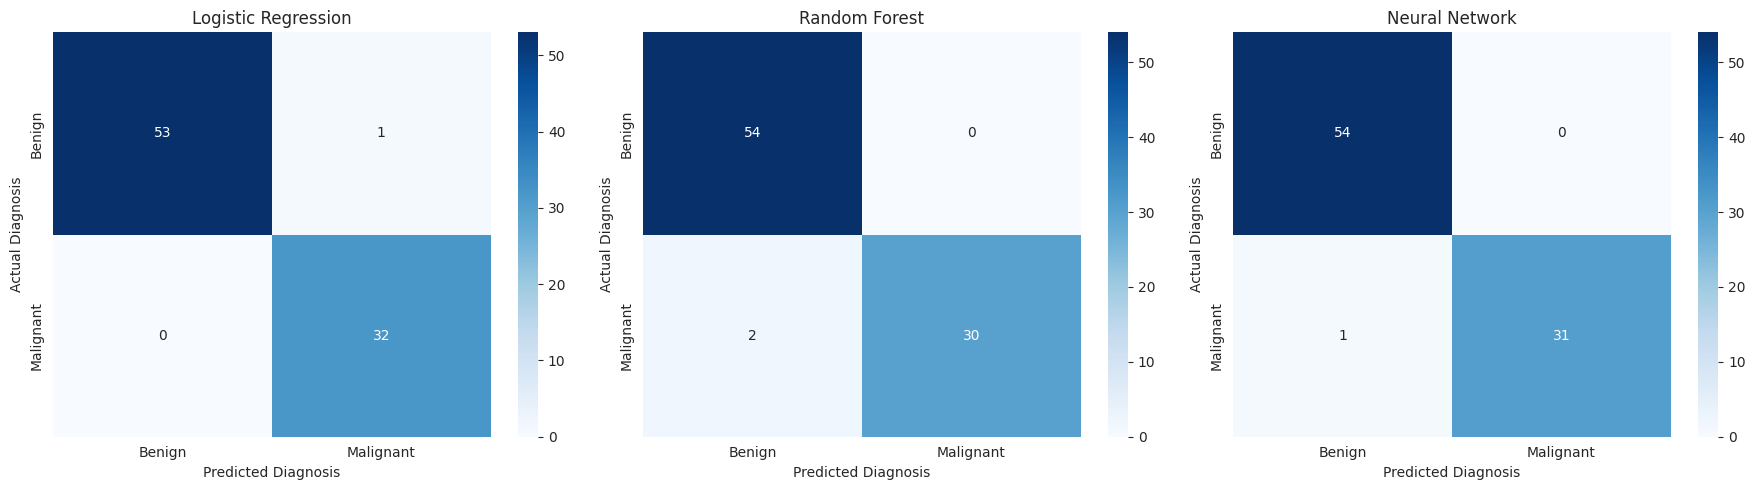

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, final_models):

    cm = confusion_matrix(
        y_test,
        test_predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Benign', 'Malignant'],
        yticklabels=['Benign', 'Malignant'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Diagnosis')
    ax.set_ylabel('Actual Diagnosis')

plt.tight_layout()
plt.show()

ROC Curve Comparison

In this step, we plot the ROC curves of the three models to compare their ability to distinguish between benign and malignant tumors at different classification thresholds. A higher AUC value indicates better classification performance.

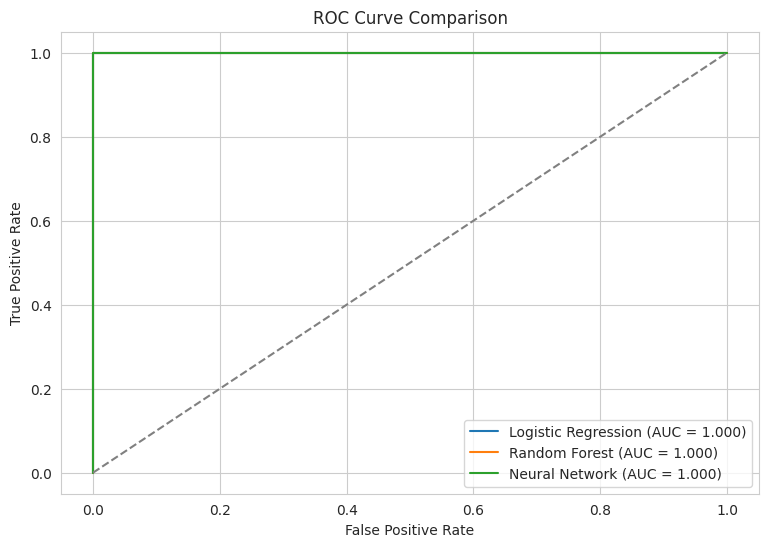

In [42]:
plt.figure(figsize=(9, 6))

for name in final_models:

    fpr, tpr, thresholds = roc_curve(
        y_test,
        test_probabilities[name]
    )

    auc_value = roc_auc_score(
        y_test,
        test_probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_value:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray'
)

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
plt.show()

Final Model Performance Comparison

In this step, we create a final comparison table showing the test performance of all three models. The results are compared using the selected evaluation metrics to identify the most suitable model for the classification task.

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.9884,0.9697,1.0000,0.9846,1.0
Random Forest,0.9767,1.0000,0.9375,0.9677,1.0
Neural Network,0.9884,1.0000,0.9688,0.9841,1.0


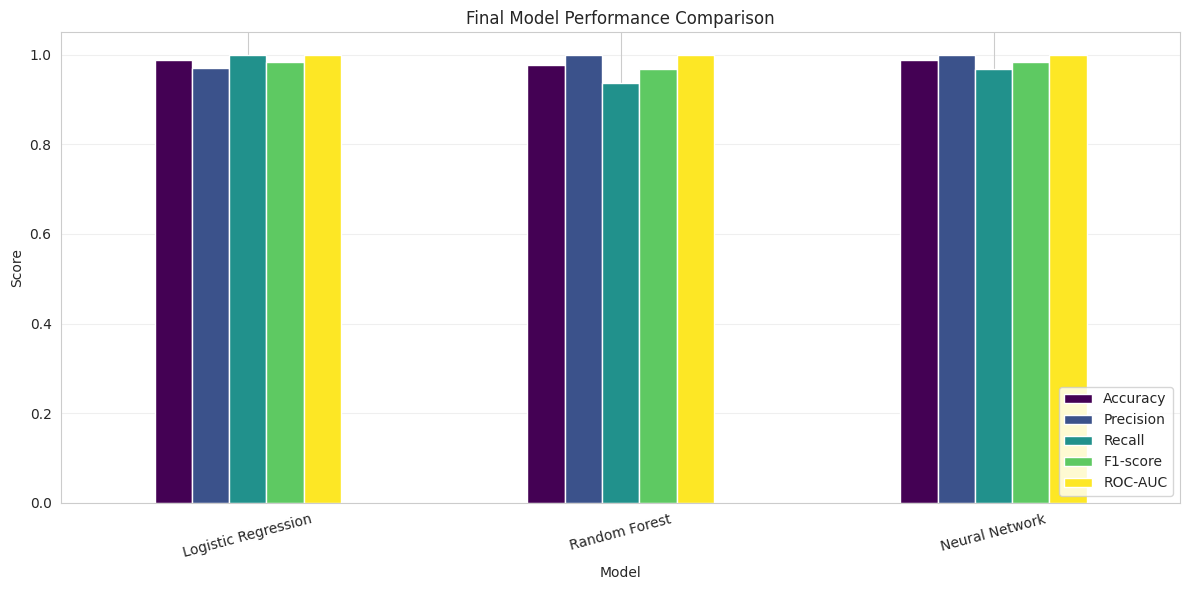

In [43]:
comparison = final_results_df.set_index('Model')

display(comparison.round(4))

comparison.plot(
    kind='bar',
    figsize=(12, 6),
    ylim=(0, 1.05),
    colormap='viridis'
)

plt.title('Final Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Selecting the Best Performing Model

In this step, we identify the best-performing model based on the test results. Since this project focuses on breast cancer classification, Recall for the malignant class is especially important because missing a malignant case can have serious consequences. We also consider F1-score and ROC-AUC when comparing the models.

In [44]:
best_model_name = (
    final_results_df
    .sort_values(
        by=['Recall', 'F1-score', 'ROC-AUC'],
        ascending=False
    )
    .iloc[0]['Model']
)

print("Best Performing Model:", best_model_name)

print("\nPerformance Results:")

display(
    final_results_df[
        final_results_df['Model'] == best_model_name
    ].round(4)
)

Best Performing Model: Logistic Regression

Performance Results:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9884,0.9697,1.0,0.9846,1.0


Part 4 Summary

In this part, we evaluated the three optimized models using the test dataset. We used different evaluation metrics, including Accuracy, Precision, Recall, F1-score, and ROC-AUC to compare their performance. Confusion matrices and ROC curves were also used to analyze the results and understand the models' ability to classify benign and malignant tumors. Finally, we compared the models to identify the best-performing model for this classification task.